# Mimir game-director workflow for Samskara

## tl;dr

The recommended production spine is not a giant GDD or an AI chat. It is a versioned evidence chain:

`experience question -> signed mechanic contract -> cheapest honest proof -> bounded Mimir change packet -> deterministic Unity skeleton -> complete playable conversation -> blind observation -> director decision -> production handoffs -> integrated vertical slice`

The human director owns vision, canon, taste, scope, and release. Mimir retrieves, cites, guides, traces, verifies, and abstains. It never decides that a mechanic is fun or promotes generated work into canon.

For Samskara, the immediate application is the existing combat G0 gate: prove readable commitment, the three-beat phrase, one-slot buffer, initiative, and contact outcomes with placeholders before Recognition, Rupture, broad content, or bespoke animation.


## Context & Methods

This notebook synthesizes five evidence layers:

1. the Samskara game-director/writer curriculum and its `question -> artifact -> proof -> observation -> decision -> canonical update` loop;
2. the Consciousness Combat GDD and its `Read -> Seize -> Express -> Recognize -> Release` combat loop;
3. the Combat Vertical Slice Production Plan and its G0-G7 mechanic-before-animation gates;
4. Hakita's ULTRAKILL development talk, especially core-loop-first design, early sound, responsive input, uncoached testing, subtraction, iteration, and the difficult final stretch;
5. official documentation and licenses for an open-source production toolchain around Unity.

### Key assumptions

- Unity and the already-established REAPER setup remain the intentional proprietary exceptions.
- The director writes Samskara's lore and makes creative decisions; AI may help retrieve, implement bounded code tasks, critique, and verify.
- External artists deliver editable source, controlled exports, provenance, and explicit rights.
- The workflow is designed for one director/developer first and expands only when a measured coordination problem exists.


In [1]:
from pathlib import Path
import yaml

repo = Path.cwd().resolve()
while repo != repo.parent and not (repo / "README.md").exists():
    repo = repo.parent
assert (repo / "README.md").exists(), "Open this notebook from inside the Moolah/Mimir repository."

sources = {
    "Mimir product map": repo / "docs/product/MIMIR_FEATURE_AND_TOOL_MAP.md",
    "Mimir AI build workflow": repo / "docs/product/AI_BUILD_WORKFLOW.md",
    "Executable workflow": repo / "docs/workflows/samskara-mechanic-production-v0.1.yaml",
    "Readable workflow": repo / "docs/product/SAMSKARA_GAME_DIRECTOR_WORKFLOW.md",
    "Open toolchain research": repo / "docs/research/2026-11-12-open-game-production-toolchain.md",
    "Samskara curriculum": Path("/home/arthrot/Documents/Unity Jazz/TOOL typeshi/Game/Samskara/Documentation/UltimateGameDirectorWriterTeachingEdition.md"),
    "Combat vertical-slice plan": Path("/home/arthrot/Documents/Unity Jazz/TOOL typeshi/Game/Samskara/Documentation/CombatVerticalSliceProductionPlan.md"),
    "Combat GDD": Path("/home/arthrot/Documents/Unity Jazz/TOOL typeshi/tmp/combat-gdd-render/consciousness_combat_game_design_document.pdf"),
}

missing = [name for name, path in sources.items() if not path.exists()]
print(f"Sources checked: {len(sources)}")
print("Missing:", missing or "none")


Sources checked: 8
Missing: none


## Results

### 1. The evidence agrees on a small fixed spine and living detail

The durable direction layer should stay short: experience promise, pillars and anti-pillars, iconic mechanic, core dialectic, loop stack, scope, and risks. A mechanic gets a one-page falsifiable contract. Mutable detail grows through implementation and playtest evidence instead of inflating an up-front GDD.

This reconciles the existing curriculum with the practical video advice. A strong vision is essential, but so is knowing which imagined features are unnecessary. The contract protects intent; the cut list protects completion.

### 2. Mimir should enforce transitions, not author taste

Each gate declares inputs, human owner, allowed actions, completion proof, failure routing, and next state. Mimir can identify missing evidence or conflicts deterministically. Only the director can approve a concept, canonize a story fact, accept art/audio, decide whether evidence warrants a design change, or ship.

### 3. Every expensive discipline waits for the contract it depends on

Bespoke animation waits for stable timing, displacement, contact, cancel, and handoff rules. Final art waits for camera distance, silhouette, state, scale, and performance budgets. Final music waits for scene function, intensity architecture, transition and loop behavior. This does not mean silence or ugly prototypes: rough sound and clear placeholders enter immediately because they affect feel and comprehension.


In [2]:
workflow_path = repo / "docs/workflows/samskara-mechanic-production-v0.1.yaml"
workflow = yaml.safe_load(workflow_path.read_text())

states = workflow["states"]
state_ids = [state["id"] for state in states]
terminal_ids = set(workflow["terminal_states"])
known_targets = set(state_ids) | terminal_ids

problems = []
for state in states:
    for required in ("id", "owner", "required_inputs", "allowed_actions", "required_artifacts", "exit_criteria", "evidence", "on_failure"):
        if required not in state:
            problems.append(f"{state.get('id', '<unknown>')}: missing {required}")
    if "next" in state and state["next"] not in known_targets:
        problems.append(f"{state['id']}: unknown next target {state['next']}")
    for label, target in state.get("transitions", {}).items():
        if target not in known_targets:
            problems.append(f"{state['id']}/{label}: unknown target {target}")

print("Workflow:", workflow["title"], workflow["version"])
print("Active states:", len(states))
print("Terminal states:", ", ".join(sorted(terminal_ids)))
print("Structural problems:", problems or "none")
assert not problems


Workflow: Samskara mechanic production 0.1.0
Active states: 12
Terminal states: blocked, complete, cut
Structural problems: none


In [3]:
from textwrap import shorten

print(f"{'Stage':<25} {'Owner':<12} {'Evidence required'}")
print("-" * 90)
for state in states:
    evidence = ", ".join(state["evidence"])
    print(f"{state['id']:<25} {state['owner']:<12} {shorten(evidence, width=48, placeholder='...')}")


Stage                     Owner        Evidence required
------------------------------------------------------------------------------------------
idea_triage               director     signed_idea_card
concept_check             director     concept_check_record
mechanic_contract         director     signed_mechanic_narrative_contract
proof_selection           director     prototype_brief
change_packet             developer    approved_change_packet
deterministic_skeleton    developer    commit, test_output, sandbox_capture,...
playable_conversation     director     build_id, commit, capture,...
blind_playtest            director     playtest_records, optional_recording_reference
director_decision         director     signed_decision_record, canonical_diff
production_contracts      director     approved_handoffs, asset_registry_entries
integration               developer    build_id, commit, test_output, capture,...
vertical_slice_gate       director     build_id, commit, test_output,

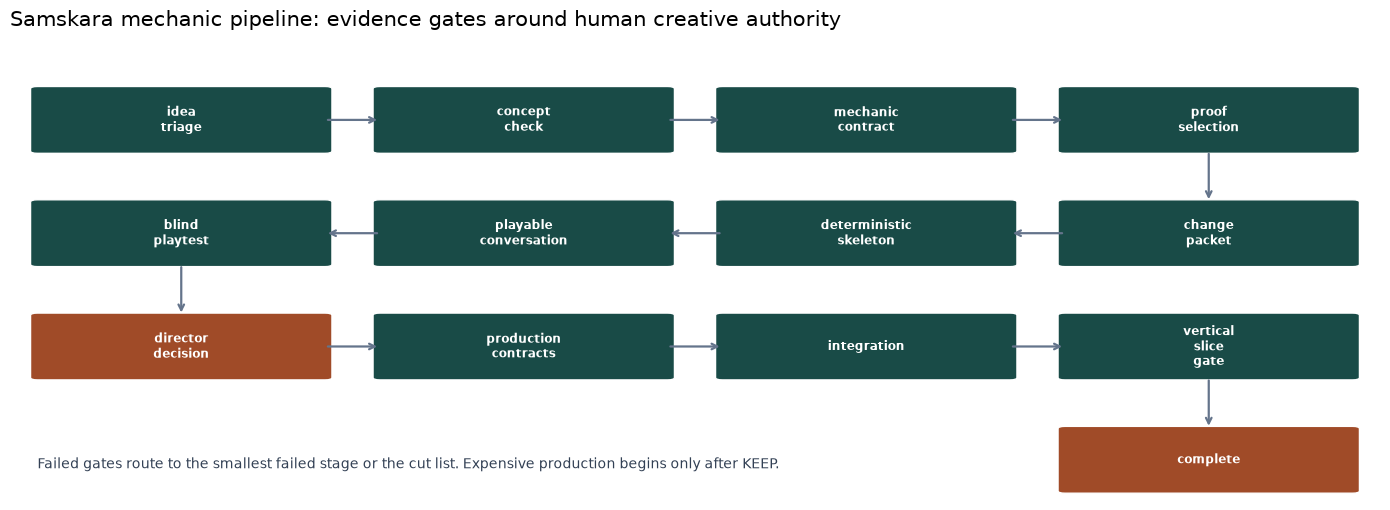

In [4]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

main_flow = [
    "idea_triage", "concept_check", "mechanic_contract", "proof_selection",
    "change_packet", "deterministic_skeleton", "playable_conversation",
    "blind_playtest", "director_decision", "production_contracts",
    "integration", "vertical_slice_gate", "complete",
]

fig, ax = plt.subplots(figsize=(14, 5.2))
ax.set_xlim(0, 4)
ax.set_ylim(-3.5, 0.5)
ax.axis("off")

positions = {}
for i, stage in enumerate(main_flow):
    row, col = divmod(i, 4)
    if row % 2 == 1:
        col = 3 - col
    x, y = col + 0.08, -row
    positions[stage] = (x, y)
    color = "#194b47" if stage not in {"director_decision", "complete"} else "#a04b28"
    box = FancyBboxPatch((x, y - 0.42), 0.84, 0.55, boxstyle="round,pad=0.02", facecolor=color, edgecolor="white")
    ax.add_patch(box)
    ax.text(x + 0.42, y - 0.145, stage.replace("_", "\n"), ha="center", va="center", color="white", fontsize=8.7, weight="bold")

for a, b in zip(main_flow, main_flow[1:]):
    x1, y1 = positions[a]
    x2, y2 = positions[b]
    if y1 == y2 and x2 > x1:
        start, end = (x1 + 0.84, y1 - 0.145), (x2, y2 - 0.145)
    elif y1 == y2:
        start, end = (x1, y1 - 0.145), (x2 + 0.84, y2 - 0.145)
    else:
        start, end = (x1 + 0.42, y1 - 0.42), (x2 + 0.42, y2 + 0.13)
    ax.annotate("", xy=end, xytext=start, arrowprops=dict(arrowstyle="->", color="#64748b", lw=1.6))

ax.text(0.08, -3.22, "Failed gates route to the smallest failed stage or the cut list. Expensive production begins only after KEEP.", fontsize=10, color="#334155")
ax.set_title("Samskara mechanic pipeline: evidence gates around human creative authority", fontsize=15, loc="left", pad=15)
plt.tight_layout()
plt.show()


### 4. The open-source stack stays deliberately boring

| Need | Default | Add only when |
|---|---|---|
| Direction and contracts | Markdown + Zettlr/VSCodium | Never replace plain files as authority |
| Visual thinking | Excalidraw + SVG/PNG export | A relationship is hard to understand in text |
| Work tracking | Mimir workflow + Git issues | Use Forgejo boards when external contributors create coordination load |
| Versioning | Git + Git LFS + restic | LFS only for large binaries; remote Git is not backup |
| 2D and UI | Krita + Inkscape + GIMP | Add another tool only for a measured format/production gap |
| 3D and animation | Blender | Keep `.blend` as source and controlled FBX/glTF exports for Unity |
| Music and audio | Existing REAPER setup + MuseScore + Audacity | Preserve `.rpp`, consolidated media, plug-in/version notes, stems and lossless masters |
| Interactive writing | ink + Inky | Enter Unity only after the authored branch/state question works independently |
| Localization | Unity Localization | Add self-hosted Weblate when external translators need browser collaboration |
| Telemetry | local JSONL/CSV + DuckDB | Add a server only when consented external volume justifies operations and privacy cost |

Unity and REAPER are the deliberate non-open-source exceptions. Everything around them remains inspectable and portable, with no essential workflow state trapped behind a subscription service.

### 5. The current Samskara move is G0, not a broader combat build

The workflow does not recommend implementing the complete GDD at once. The next mechanic packet should cover only:

- one authoritative combat state machine;
- one data-defined placeholder action;
- startup, commitment, active, recovery, queue, defense, locomotion, and end;
- a three-beat phrase and one-slot input buffer;
- explicit contact and initiative results;
- a target dummy, debug overlay, and rough response audio;
- EditMode tests and one editor-visible sandbox proof.

Recognition, Rupture, final animation, additional weapons, progression, bosses, and broad content remain deferred until the earlier interaction is readable and stable.


## Takeaways

1. **Adopt the executable YAML as Mimir's first real design-to-implementation workflow fixture.** It exercises authority, gating, evidence freshness, human approvals, backward routing, and terminal cut/blocked states.
2. **Use Samskara combat G0 as the pilot.** It is small enough to evaluate Mimir and already has unusually specific acceptance evidence.
3. **Build the artifact graph around stable IDs.** A mechanic ID should connect pillar, contract, decision, change packet, code, scene, asset, test, build, playtest, and final outcome.
4. **Commission final work after KEEP.** Until then, use placeholders precise enough to test timing, silhouette, information, and feeling.
5. **Preserve a public-development lane without confusing it with production truth.** Share representative builds and development material early, but never let marketing assets become the canonical design specification.

### Evidence limits

- The linked video was analyzed through its chaptered public page and a timestamped transcript mirror because YouTube blocked direct automated playback/transcript export in this environment. Important advice was treated as the speaker's reported practice, not universal law.
- The Game Design PDF and current Samskara documents provide a strong process and combat contract, but the workflow remains proposed until it is encoded and used on a real Mimir/Samskara change.
- Open-source licensing does not remove operating cost. Self-hosted Forgejo, Weblate, or telemetry services still require maintenance and backups.

### Primary artifact links

- Readable workflow: `docs/product/SAMSKARA_GAME_DIRECTOR_WORKFLOW.md`
- Executable workflow: `docs/workflows/samskara-mechanic-production-v0.1.yaml`
- Toolchain evidence: `docs/research/2026-11-12-open-game-production-toolchain.md`
- Video: <https://www.youtube.com/watch?v=LK6-_rY7GOs>
